In [1]:
import json, time
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt

PILOT = True
if PILOT:
    H, N_TRAIN, STEPS, CAL_ITERS, N_SEEDS = 64, 1000, 2000, 5, 5
else:
    H, N_TRAIN, STEPS, CAL_ITERS, N_SEEDS = 128, 2000, 2500, 7, 5
N_TEST, D_NOISE, THR = 4000, 18, 0.1
OPTS = ['adam', 'sgd']
RS = [2, 3, 5, 7]

torch.set_num_threads(2)
print('torch', torch.__version__, '| H', H, 'N_TRAIN', N_TRAIN, 'STEPS', STEPS, 'CAL_ITERS', CAL_ITERS, 'seeds', N_SEEDS)

torch 2.11.0+cpu | H 64 N_TRAIN 1000 STEPS 2000 CAL_ITERS 5 seeds 5


## data

In [2]:
def make_B(y, R, s, rng):
    # R regions of width s; region parity gives the label; 15% of each region is left empty at both edges..
    n = len(y); xb = np.zeros(n)
    for i in range(n):
        cands = [j for j in range(R) if (j % 2 == 0) == (y[i] > 0)]
        j = rng.choice(cands)
        lo, hi = j * s + 0.15 * s, (j + 1) * s - 0.15 * s
        xb[i] = rng.uniform(lo, hi) - R * s / 2
    return xb

def make_data(n, R, s, rng):
    y = rng.choice([-1, 1], size=n)
    xa = y * rng.uniform(0.5, 1.5, size=n)# feature A: linear, distance from boundary >= 0.5
    xb = make_B(y, R, s, rng)      # feature B: R-slab
    noise = rng.normal(size=(n, D_NOISE))
    X = np.column_stack([xa, xb, noise]).astype(np.float32)
    return X, ((y + 1) // 2).astype(np.float32)

def make_single(n, R, s, which, rng):
    # keep only one feature informative n replace other coordinate with noise
    X, y = make_data(n, R, s, rng)
    other = rng.normal(size=n)
    if which == 'A': X[:, 1] = other
    else:            X[:, 0] = other
    return X, y

## Model, training, reliance

In [3]:
def make_net(opt_name, seed):
    torch.manual_seed(seed)
    m = nn.Sequential(nn.Linear(2 + D_NOISE, H), nn.ReLU(), nn.Linear(H, H), nn.ReLU(), nn.Linear(H, 1))
    if opt_name == 'adam':
        opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    else:
        opt = torch.optim.SGD(m.parameters(), lr=0.05, momentum=0.9)
    return m, opt

def train(X, y, opt_name, seed, steps=None):
    steps = steps or STEPS
    m, opt = make_net(opt_name, seed)
    Xt, yt = torch.tensor(X), torch.tensor(y)
    lf = nn.BCEWithLogitsLoss()
    hit = steps                                   # steps to reach loss < THR (= steps if never reached)
    for t in range(steps):
        opt.zero_grad()
        loss = lf(m(Xt).squeeze(1), yt)
        loss.backward(); opt.step()
        if hit == steps and loss.item() < THR:
            hit = t
    return m, hit

def acc(m, X, y):
    with torch.no_grad():
        return ((m(torch.tensor(X)).squeeze(1) > 0).float() == torch.tensor(y)).float().mean().item()

def reliance(m, X, y, rng):
    # accuracy drop when one feature coordinate is permuted across test examples
    base = acc(m, X, y); drops = []
    for c in (0, 1):
        Xp = X.copy(); Xp[:, c] = rng.permutation(Xp[:, c])
        drops.append(base - acc(m, Xp, y))
    return base, drops[0], drops[1]

## speed matching

In [4]:
def steps_alone(R, s, which, opt_name, seeds=(100, 101)):
    rng = np.random.default_rng(7)
    X, y = make_single(N_TRAIN, R, s, which, rng)
    return float(np.mean([train(X, y, opt_name, sd)[1] for sd in seeds]))

def calibrate(R, opt_name, target):
    # bisection on log(scale) in [0.3, 30]: larger scale makes B faster
    lo, hi = np.log(0.3), np.log(30.0)
    for _ in range(CAL_ITERS):
        mid = (lo + hi) / 2
        st = steps_alone(R, np.exp(mid), 'B', opt_name)
        if st > target: lo = mid
        else:           hi = mid
    return float(np.exp((lo + hi) / 2))

## grid run

In [5]:
rows = []
t0 = time.time()
for opt_name in OPTS:
    target = steps_alone(2, 2.0, 'A', opt_name)   # A alone (B's coordinate is replaced by noise)
    print(f'{opt_name}: steps for A alone to reach loss<{THR}: {target:.0f}   [{time.time()-t0:.0f}s]', flush=True)
    for R in RS:
        s_matched = calibrate(R, opt_name, target)
        for cond, s in [('unmatched', 1.0), ('matched', s_matched)]:
            stB = steps_alone(R, s, 'B', opt_name)
            for seed in range(N_SEEDS):
                rng = np.random.default_rng(1000 + seed)
                X, y = make_data(N_TRAIN, R, s, rng)
                Xte, yte = make_data(N_TEST, R, s, rng)
                m, _ = train(X, y, opt_name, seed)
                b, dA, dB = reliance(m, Xte, yte, np.random.default_rng(seed))
                rows.append(dict(opt=opt_name, R=R, cond=cond, scale=s, stepsA=target, stepsB=stB,
                                 seed=seed, acc=b, dA=dA, dB=dB))
            g = pd.DataFrame([r for r in rows if r['opt'] == opt_name and r['R'] == R and r['cond'] == cond])
            print(f'{opt_name:4s} R={R} {cond:9s} scale={s:5.2f} stepsB={stB:5.0f}  '
                  f'acc={g.acc.mean():.3f}  dropA={g.dA.mean():.3f}  dropB={g.dB.mean():.3f}   [{time.time()-t0:.0f}s]', flush=True)
df = pd.DataFrame(rows)
df.to_csv('results.csv', index=False)
print('done in %.1f min' % ((time.time() - t0) / 60))

adam: steps for A alone to reach loss<0.1: 64   [17s]
adam R=2 unmatched scale= 1.00 stepsB=   82  acc=1.000  dropA=0.484  dropB=0.016   [91s]
adam R=2 matched   scale= 2.09 stepsB=   66  acc=1.000  dropA=0.251  dropB=0.251   [119s]
adam R=3 unmatched scale= 1.00 stepsB=  133  acc=1.000  dropA=0.503  dropB=0.000   [197s]
adam R=3 matched   scale=27.92 stepsB=   74  acc=1.000  dropA=0.057  dropB=0.442   [224s]
adam R=5 unmatched scale= 1.00 stepsB=  197  acc=1.000  dropA=0.499  dropB=0.000   [291s]
adam R=5 matched   scale=27.92 stepsB=  173  acc=1.000  dropA=0.496  dropB=0.002   [317s]
adam R=7 unmatched scale= 1.00 stepsB=  206  acc=1.000  dropA=0.499  dropB=-0.000   [389s]
adam R=7 matched   scale=27.92 stepsB=  658  acc=1.000  dropA=0.498  dropB=0.001   [418s]
sgd: steps for A alone to reach loss<0.1: 36   [424s]
sgd  R=2 unmatched scale= 1.00 stepsB=   57  acc=1.000  dropA=0.496  dropB=0.002   [477s]
sgd  R=2 matched   scale= 1.81 stepsB=   38  acc=1.000  dropA=0.334  dropB=0.170  

In [6]:
g = df.groupby(['opt', 'R', 'cond'], sort=False).agg(
    scale=('scale', 'first'), stepsA=('stepsA', 'first'), stepsB=('stepsB', 'first'),
    acc=('acc', 'mean'), dropA=('dA', 'mean'), dropA_sd=('dA', 'std'),
    dropB=('dB', 'mean'), dropB_sd=('dB', 'std'), n=('seed', 'count')).reset_index()
g['speed_ratio'] = g.stepsB / g.stepsA
pd.set_option('display.width', 200)
display(g.round(3))

,opt,R,cond,scale,stepsA,stepsB,acc,dropA,dropA_sd,dropB,dropB_sd,n,speed_ratio
0,adam,2,unmatched,1.000,64.5,82.5,1.000,0.484,0.009,0.016,0.007,5,1.279
1,adam,2,matched,2.093,64.5,65.5,1.000,0.251,0.033,0.251,0.027,5,1.016
2,adam,3,unmatched,1.000,64.5,133.0,1.000,0.503,0.011,0.000,0.000,5,2.062
3,adam,3,matched,27.917,64.5,74.5,1.000,0.057,0.010,0.442,0.007,5,1.155
4,adam,5,unmatched,1.000,64.5,197.0,1.000,0.499,0.007,0.000,0.000,5,3.054
5,adam,5,matched,27.917,64.5,173.0,1.000,0.496,0.007,0.002,0.001,5,2.682
6,adam,7,unmatched,1.000,64.5,206.0,1.000,0.499,0.008,-0.000,0.000,5,3.194
7,adam,7,matched,27.917,64.5,657.5,1.000,0.498,0.008,0.001,0.000,5,10.194
8,sgd,2,unmatched,1.000,36.0,57.0,1.000,0.496,0.005,0.002,0.001,5,1.583
9,sgd,2,matched,1.813,36.0,37.5,1.000,0.334,0.020,0.170,0.014,5,1.042


In [7]:
def cell(opt, R, cond):
    r = g[(g.opt == opt) & (g.R == R) & (g.cond == cond)]
    return r.iloc[0] if len(r) else None

def report(name, ok):
    print(('PASS  ' if ok else 'CHECK ') + name)

# C1: unmatched, every R and optimizer: the network uses A and ignores B
ok = all(cell(o, R, 'unmatched').dropA > 0.40 and cell(o, R, 'unmatched').dropB < 0.05 for o in OPTS for R in RS)
report('C1  Unmatched: shuffling A costs > 0.40 accuracy and shuffling B costs < 0.05, for every R and optimizer', ok)

# C2: R=2 unmatched, both features linear, still prefers A
ok = all(cell(o, 2, 'unmatched').dropA > cell(o, 2, 'unmatched').dropB + 0.3 for o in OPTS)
report('C2  Unmatched R=2 (both linear): network still relies on A', ok)
print('      B margin 0.15*s vs A margin 0.5, and B-alone speed ratio:',
      {o: round(cell(o, 2, 'unmatched').speed_ratio, 2) for o in OPTS})

# C3: matched R=2: speeds within 10% and preference moves to B
ok = all(abs(cell(o, 2, 'matched').speed_ratio - 1) <= 0.10 and cell(o, 2, 'matched').dropB > cell(o, 2, 'matched').dropA for o in OPTS)
report('C3  Matched R=2: speed within 10% and the network relies more on B than on A', ok)

# C4: matched R=3 with SGD: the cleanest matched cell with a nonlinear B
c = cell('sgd', 3, 'matched')
report('C4  SGD, matched R=3: speed within 10% and the network relies more on B (3-slab) than on A',
       abs(c.speed_ratio - 1) <= 0.10 and c.dropB > c.dropA)
print('      speed ratio %.2f, scale %.2f, dropA %.3f, dropB %.3f' % (c.speed_ratio, c.scale, c.dropA, c.dropB))

# C5: matched R>=5: calibration cannot match speed, or training fails, so the cell is not a valid test
for o in OPTS:
    for R in (5, 7):
        c = cell(o, R, 'matched')
        invalid = abs(c.speed_ratio - 1) > 0.10 or c.acc < 0.9
        report(f'C5  {o} matched R={R}: not a valid matched test (speed ratio {c.speed_ratio:.2f}, accuracy {c.acc:.2f})', invalid)

PASS  C1  Unmatched: shuffling A costs > 0.40 accuracy and shuffling B costs < 0.05, for every R and optimizer
PASS  C2  Unmatched R=2 (both linear): network still relies on A
      B margin 0.15*s vs A margin 0.5, and B-alone speed ratio: {'adam': np.float64(1.28), 'sgd': np.float64(1.58)}
CHECK C3  Matched R=2: speed within 10% and the network relies more on B than on A
PASS  C4  SGD, matched R=3: speed within 10% and the network relies more on B (3-slab) than on A
      speed ratio 0.99, scale 4.96, dropA 0.247, dropB 0.260
PASS  C5  adam matched R=5: not a valid matched test (speed ratio 2.68, accuracy 1.00)
PASS  C5  adam matched R=7: not a valid matched test (speed ratio 10.19, accuracy 1.00)
PASS  C5  sgd matched R=5: not a valid matched test (speed ratio 55.56, accuracy 0.70)
PASS  C5  sgd matched R=7: not a valid matched test (speed ratio 55.56, accuracy 0.50)


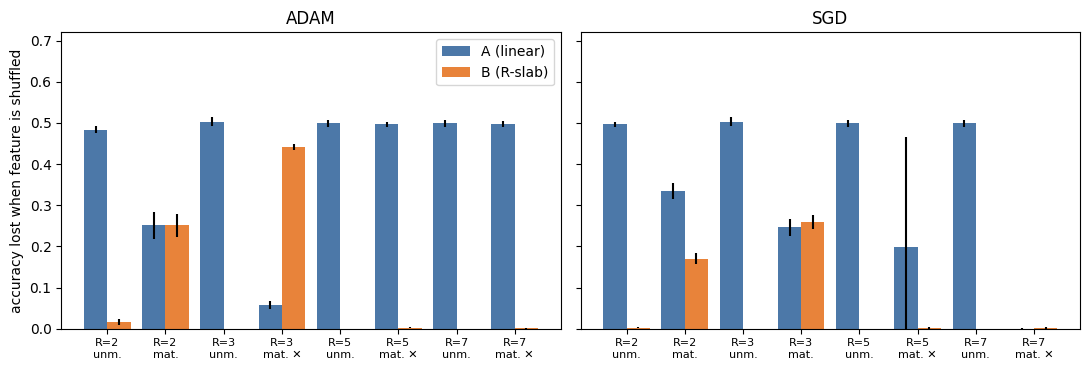

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, o in zip(axes, OPTS):
    labels, xs = [], []
    for i, (R, cond) in enumerate([(R, c) for R in RS for c in ('unmatched', 'matched')]):
        r = cell(o, R, cond)
        valid = cond == 'unmatched' or (abs(r.speed_ratio - 1) <= 0.10 and r.acc >= 0.9)
        ax.bar(i - 0.2, r.dropA, 0.4, yerr=r.dropA_sd, color='#4c78a8', label='A (linear)' if i == 0 else None)
        ax.bar(i + 0.2, r.dropB, 0.4, yerr=r.dropB_sd, color='#e8833a', label='B (R-slab)' if i == 0 else None)
        labels.append(f'R={R}\n{cond[:3]}.' + ('' if valid else ' \u2715'))
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8)
    ax.set_title(o.upper()); ax.set_ylim(0, 0.72)
axes[0].set_ylabel('accuracy lost when feature is shuffled'); axes[0].legend(loc='upper right')
plt.tight_layout(); plt.show()